In [2]:
import os, sys, json
PROJECT_ROOT = os.path.abspath("..")
sys.path.append(PROJECT_ROOT)

import numpy as np
import tensorflow as tf
from tensorflow import keras
from sklearn.utils.class_weight import compute_class_weight
from src.data import load_split, make_dataset, CLASSES

train_df, val_df, test_df = load_split(PROJECT_ROOT)
y_val = val_df["label"].values

idx = np.arange(len(CLASSES))
w = compute_class_weight("balanced", classes=idx, y=train_df["label"].values)
class_weight = {int(i): float(x) for i, x in zip(idx, w)}
class_weight_sqrt = {i: float(np.sqrt(x)) for i, x in class_weight.items()}

model = keras.models.load_model(os.path.join(PROJECT_ROOT, "models", "mobilenetv2_head_sqrt.keras"))
print("Loaded:", model.name, "| weights:", {CLASSES[i]: round(x, 2) for i, x in class_weight_sqrt.items()})

Loaded: mobilenetv2_sqrtweights | weights: {'akiec': 2.09, 'bcc': 1.65, 'bkl': 1.14, 'df': 3.63, 'mel': 1.13, 'nv': 0.46, 'vasc': 3.18}


In [3]:
import time
from sklearn.metrics import balanced_accuracy_score, f1_score, recall_score, precision_score

MODELS_DIR = os.path.join(PROJECT_ROOT, "models")

# Find the MobileNetV2 base inside the loaded model
base = next(l for l in model.layers if isinstance(l, keras.Model))
print("Base layers:", len(base.layers))

base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
# Keep BatchNorm layers frozen (standard practice with small datasets)
for layer in base.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
print("Trainable params now:", trainable)

model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

train_ds = make_dataset(train_df, batch_size=32, training=True)
val_ds = make_dataset(val_df, batch_size=32, training=False)

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7, verbose=1),
    keras.callbacks.ModelCheckpoint(os.path.join(MODELS_DIR, "mobilenetv2_finetuned_sqrt.keras"),
                                    monitor="val_loss", save_best_only=True),
]

t0 = time.time()
hist = model.fit(train_ds, validation_data=val_ds, epochs=15,
                 class_weight=class_weight_sqrt, callbacks=callbacks)
print(f"\nTraining time: {(time.time() - t0) / 60:.1f} min")
best_epoch = int(np.argmin(hist.history["val_loss"])) + 1
print("Best epoch:", best_epoch)

val_probs = model.predict(val_ds, verbose=0)
val_pred = val_probs.argmax(axis=1)
print("Val accuracy         :", round((val_pred == y_val).mean(), 4))
print("Val balanced accuracy:", round(balanced_accuracy_score(y_val, val_pred), 4))
print("Val macro F1         :", round(f1_score(y_val, val_pred, average="macro"), 4))
print("mel recall / precision:",
      round(recall_score(y_val, val_pred, labels=[4], average=None)[0], 4), "/",
      round(precision_score(y_val, val_pred, labels=[4], average=None)[0], 4))

res = {"model": "mobilenetv2_finetuned_sqrt", "val_accuracy": float((val_pred == y_val).mean()),
       "val_balanced_accuracy": float(balanced_accuracy_score(y_val, val_pred)),
       "val_macro_f1": float(f1_score(y_val, val_pred, average="macro")),
       "mel_recall": float(recall_score(y_val, val_pred, labels=[4], average=None)[0]),
       "mel_precision": float(precision_score(y_val, val_pred, labels=[4], average=None)[0]),
       "best_epoch": best_epoch}
with open(os.path.join(PROJECT_ROOT, "results", "finetuned_mobilenet_sqrt.json"), "w") as f:
    json.dump(res, f, indent=2)

Base layers: 154
Trainable params now: 1519687
Epoch 1/15


<project>\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


219/219 ━━━━━━━━━━━━━━━━━━━━ 241s 1s/step - accuracy: 0.7542 - loss: 0.6758 - val_accuracy: 0.7245 - val_loss: 0.7480 - learning_rate: 1.0000e-05
Epoch 2/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 319s 1s/step - accuracy: 0.7753 - loss: 0.6124 - val_accuracy: 0.7317 - val_loss: 0.7303 - learning_rate: 1.0000e-05
Epoch 3/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 287s 1s/step - accuracy: 0.7755 - loss: 0.5845 - val_accuracy: 0.7617 - val_loss: 0.6664 - learning_rate: 1.0000e-05
Epoch 4/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 333s 2s/step - accuracy: 0.7886 - loss: 0.5579 - val_accuracy: 0.7513 - val_loss: 0.6586 - learning_rate: 1.0000e-05
Epoch 5/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 344s 2s/step - accuracy: 0.7959 - loss: 0.5347 - val_accuracy: 0.7552 - val_loss: 0.6655 - learning_rate: 1.0000e-05
Epoch 6/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 305s 1s/step - accuracy: 0.8079 - loss: 0.5199 - val_accuracy: 0.7617 - val_loss: 0.6531 - learning_rate: 1.0000e-05
Epoch 7/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 317s 1s/step - accuracy: 0.81

In [4]:
import json
from sklearn.metrics import precision_recall_curve

mel_p = val_probs[:, 4]
is_mel = (y_val == 4).astype(int)
prec, rec, thr = precision_recall_curve(is_mel, mel_p)

print("threshold | mel recall | mel precision")
for t in [0.5, 0.4, 0.3, 0.25, 0.2, 0.15, 0.1]:
    pred_mel = mel_p >= t
    tp = (pred_mel & (is_mel == 1)).sum()
    print(f"{t:9.2f} | {tp / is_mel.sum():10.3f} | {tp / max(pred_mel.sum(), 1):13.3f}  (flagged {pred_mel.sum()})")

print(json.load(open(os.path.join(PROJECT_ROOT, "results", "finetuned_mobilenet_sqrt.json"))))

threshold | mel recall | mel precision
     0.50 |      0.376 |         0.610  (flagged 105)
     0.40 |      0.471 |         0.526  (flagged 152)
     0.30 |      0.565 |         0.430  (flagged 223)
     0.25 |      0.635 |         0.397  (flagged 272)
     0.20 |      0.665 |         0.352  (flagged 321)
     0.15 |      0.694 |         0.304  (flagged 388)
     0.10 |      0.794 |         0.272  (flagged 496)
{'model': 'mobilenetv2_finetuned_sqrt', 'val_accuracy': 0.7800261096605744, 'val_balanced_accuracy': 0.5837426622829022, 'val_macro_f1': 0.5646046094887145, 'mel_recall': 0.47058823529411764, 'mel_precision': 0.5369127516778524, 'best_epoch': 13}


              precision    recall  f1-score   support

       akiec      0.448     0.588     0.508        51
         bcc      0.605     0.597     0.601        77
         bkl      0.528     0.599     0.561       157
          df      0.667     0.105     0.182        19
         mel      0.537     0.471     0.502       170
          nv      0.900     0.893     0.896      1034
        vasc      0.606     0.833     0.702        24

    accuracy                          0.780      1532
   macro avg      0.613     0.584     0.565      1532
weighted avg      0.784     0.780     0.778      1532



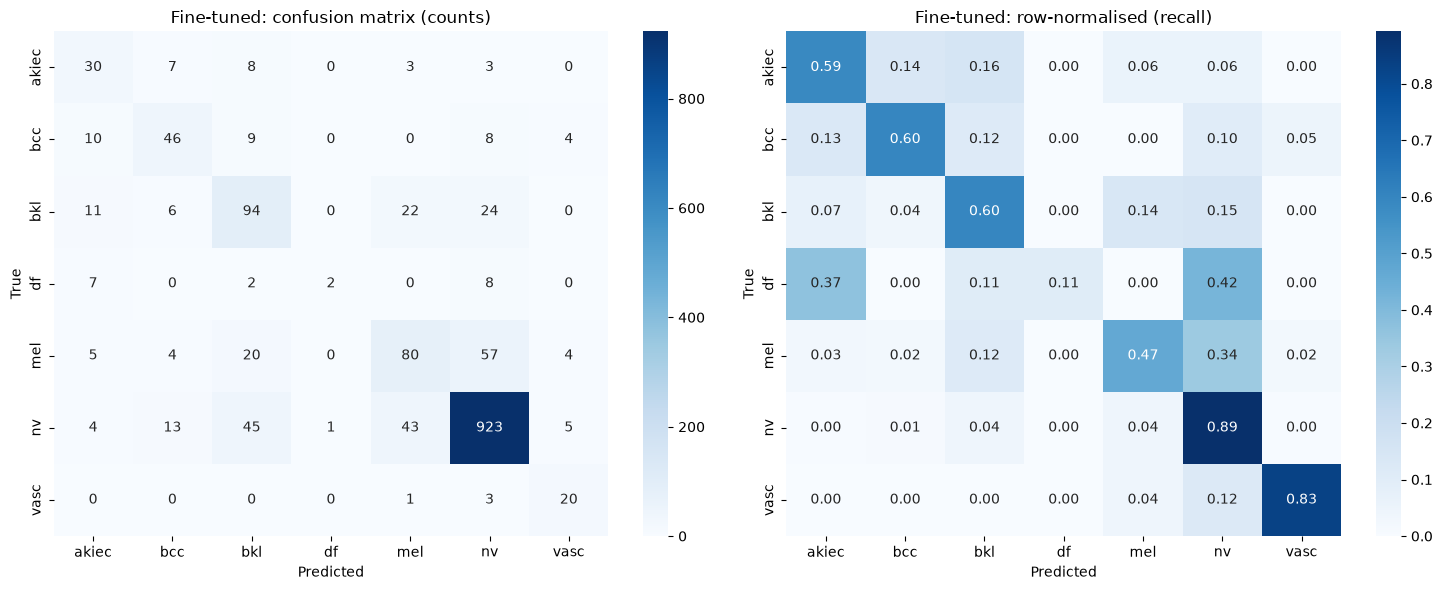

ROC-AUC akiec : 0.949
ROC-AUC bcc   : 0.969
ROC-AUC bkl   : 0.898
ROC-AUC df    : 0.932
ROC-AUC mel   : 0.861
ROC-AUC nv    : 0.924
ROC-AUC vasc  : 0.996


In [5]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import seaborn as sns
import matplotlib.pyplot as plt

print(classification_report(y_val, val_pred, target_names=CLASSES, digits=3))

cm = confusion_matrix(y_val, val_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0])
axes[0].set_title("Fine-tuned: confusion matrix (counts)")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1])
axes[1].set_title("Fine-tuned: row-normalised (recall)")
for ax in axes:
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout(); plt.show()

for i, c in enumerate(CLASSES):
    auc = roc_auc_score((y_val == i).astype(int), val_probs[:, i])
    print(f"ROC-AUC {c:6s}: {auc:.3f}")

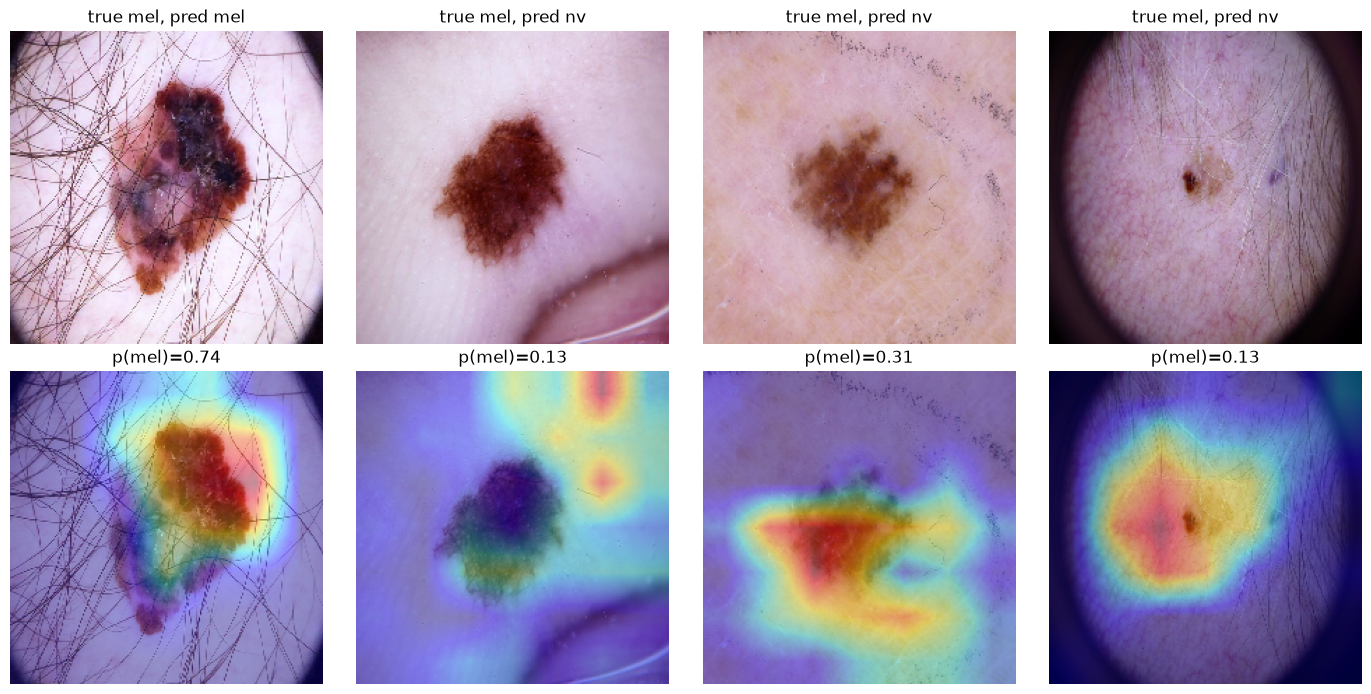

In [7]:
import cv2

# Locate the base and its last conv feature map
base = next(l for l in model.layers if isinstance(l, keras.Model))
last_conv = base.get_layer("out_relu")  # MobileNetV2's final activation (7x7x1280)

# Build the model in two parts: image -> feature map, feature map -> prediction
feat_model = keras.Model(base.input, last_conv.output)
head_layers = [l for l in model.layers if not isinstance(l, (keras.layers.InputLayer, keras.Model, keras.layers.Rescaling))]

def gradcam(img_uint8, class_idx=None):
    x = tf.convert_to_tensor(img_uint8[None].astype("float32"))
    x_scaled = x / 127.5 - 1.0
    with tf.GradientTape() as tape:
        fmap = feat_model(x_scaled, training=False)
        tape.watch(fmap)
        h = fmap
        for l in head_layers:
            h = l(h, training=False) if "dropout" in l.name else l(h)
        if class_idx is None:
            class_idx = int(tf.argmax(h[0]))
        score = h[0, class_idx]
    grads = tape.gradient(score, fmap)
    weights = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(fmap * weights[:, None, None, :], axis=-1))[0].numpy()
    cam = cam / (cam.max() + 1e-8)
    return cv2.resize(cam, (224, 224)), class_idx, h[0].numpy()

# Show 4 missed melanomas (true mel, predicted something else)
miss = np.where((y_val == 4) & (val_pred != 4))[0][:4]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for k, i in enumerate(miss):
    img = np.array(tf.keras.utils.load_img(val_df["abs_path"].iloc[i], target_size=(224, 224)))
    cam, pred, probs = gradcam(img)
    axes[0, k].imshow(img); axes[0, k].axis("off")
    axes[0, k].set_title(f"true mel, pred {CLASSES[pred]}")
    axes[1, k].imshow(img); axes[1, k].imshow(cam, cmap="jet", alpha=0.4); axes[1, k].axis("off")
    axes[1, k].set_title(f"p(mel)={probs[4]:.2f}")
plt.tight_layout(); plt.show()

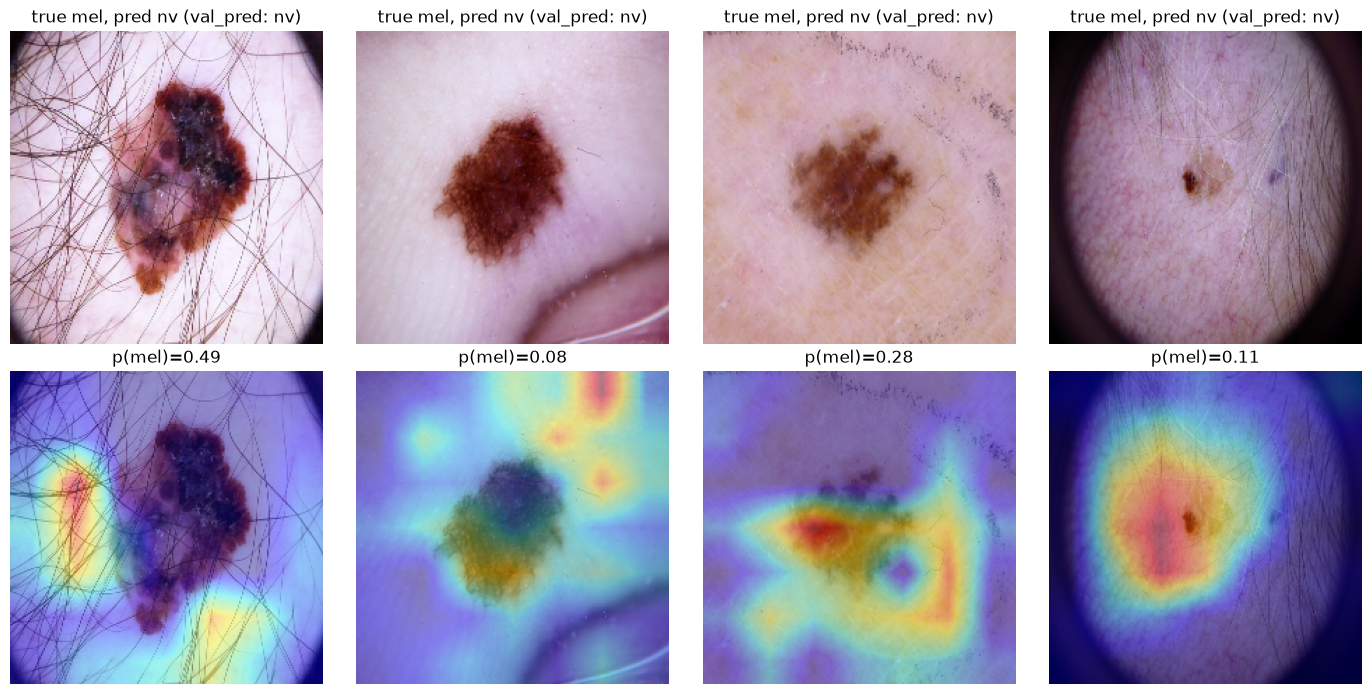

In [8]:
def load_like_pipeline(path):
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    return tf.image.resize(img, (224, 224)).numpy()   # float32, 0-255, same as training

miss = np.where((y_val == 4) & (val_pred != 4))[0][:4]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for k, i in enumerate(miss):
    img = load_like_pipeline(val_df["abs_path"].iloc[i])
    cam, pred, probs = gradcam(img)
    axes[0, k].imshow(img.astype("uint8")); axes[0, k].axis("off")
    axes[0, k].set_title(f"true mel, pred {CLASSES[pred]} (val_pred: {CLASSES[val_pred[i]]})")
    axes[1, k].imshow(img.astype("uint8")); axes[1, k].imshow(cam, cmap="jet", alpha=0.4); axes[1, k].axis("off")
    axes[1, k].set_title(f"p(mel)={probs[4]:.2f}")
plt.tight_layout(); plt.show()